# 01. Preparação dos dados e análise exploratória (EDA)

**Projeto:** Risco de avaliação negativa em pedidos de e-commerce (Olist)
**Equipe 4:** Eduarda, Eduardo e Anna. Aprendizagem de Máquina, Engenharia de Software, Católica SC.

**Objetivo deste notebook**
1. Juntar as tabelas do Olist em **uma linha por pedido entregue**.
2. Criar o alvo: `negativa = 1` se a nota da avaliação for 1 ou 2, senão 0.
3. Justificar cada tratamento (nulos, pedidos não entregues, vazamento de alvo).
4. Explorar os dados e salvar os gráficos em `img/` para o README.

O código de junção fica em `src/preparacao.py`, porque o notebook 02, o app e o script de linha de comando precisam montar os dados **exatamente do mesmo jeito**.

In [1]:
import sys
from pathlib import Path

# Permite importar a pasta src/ rodando o notebook a partir de notebooks/ ou da raiz
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.preparacao import carregar_tabelas, montar_base
from src.config import nome_categoria
from src.graficos import aplicar_estilo, salvar, linha_taxa_base, AZUL, VERMELHO, CINZA

aplicar_estilo()
pd.set_option("display.max_columns", 40)

## 1. Os dados

Fonte: *Brazilian E-Commerce Public Dataset by Olist*, no Kaggle (https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce).
São cerca de 100 mil pedidos feitos entre 2016 e 2018 em vários marketplaces brasileiros, distribuídos em 9 tabelas ligadas por chaves (`order_id`, `customer_id`, `product_id`, `seller_id`).

Usamos 8 tabelas. A de geolocalização (CEP para latitude e longitude) ficou de fora: a UF do cliente e do vendedor já está nas tabelas de clientes e vendedores, e o arquivo é o maior do dataset.

In [2]:
tabelas = carregar_tabelas()
pd.DataFrame(
    {"linhas": {k: len(v) for k, v in tabelas.items()},
     "colunas": {k: v.shape[1] for k, v in tabelas.items()}}
)

,linhas,colunas
orders,99441,8
items,112650,7
payments,103886,5
reviews,99224,7
customers,99441,5
sellers,3095,4
products,32951,9
traducao,71,2


In [3]:
tabelas["reviews"].head(3)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24


## 2. Vazamento de alvo: o que NÃO pode entrar no modelo

**Vazamento de alvo** (*target leakage*) acontece quando o modelo usa uma informação que só existe **depois** do que queremos prever, ou que é praticamente a própria resposta. O modelo fica ótimo no notebook e inútil na prática.

Na tabela de avaliações, ficam **fora das variáveis**:

| Coluna | Por que fica de fora |
|---|---|
| `review_comment_title`, `review_comment_message` | O cliente escreve junto com a nota. Se ele já escreveu "produto quebrado", já avaliou. |
| `review_creation_date`, `review_answer_timestamp` | Só existem depois que a pesquisa é enviada e respondida. |
| `review_score` | É o próprio alvo. |

As datas da avaliação são usadas **apenas** para escolher qual avaliação manter quando o pedido tem mais de uma, nunca como variável. O texto aparece só no notebook 02, **depois** do modelo pronto, para entender os erros.

O nosso cenário de uso é: o pedido foi entregue e o cliente ainda não avaliou. Nesse momento sabemos itens, valores, frete, pagamento, estados e o atraso da entrega.

## 3. Tratamentos e por que cada um foi feito

| Decisão | Justificativa |
|---|---|
| Manter só pedidos com status `delivered` e data de entrega preenchida | O atendimento age entre a entrega e a avaliação. Pedidos cancelados ou não entregues são outro problema (o cliente nem recebeu) e não têm atraso calculável. |
| Descartar pedidos sem avaliação | Sem nota não há alvo para aprender. |
| Pedido com mais de uma avaliação: manter a mais recente | Garante uma linha por pedido. A mais recente reflete a opinião final do cliente. |
| Pedido com vários itens: somar valor e frete, contar itens | O cliente avalia o pedido inteiro. |
| Categoria e vendedor do **item mais caro** | É o produto que mais pesa na experiência e no valor do pedido. |
| Pagamento: forma com **maior valor pago** | Alguns pedidos combinam voucher e cartão. Fica a forma principal e suas parcelas. |
| Categoria nula vira `sem_categoria` | São cerca de 1,4% dos pedidos. Excluir perderia dados, e "sem categoria" pode ser um sinal (cadastro incompleto). |
| Atraso e tempo de entrega em **dias inteiros** | O atendimento pensa em dias, e o app usa um controle em dias. |

In [4]:
base = montar_base(tabelas)
print(f"\nBase final: {base.shape[0]:,} pedidos e {base.shape[1]} colunas".replace(",", "."))

Pedidos no dataset                              99.441
Pedidos entregues com data de entrega           96.470
... e com avaliação                             95.824
... e com itens                                 95.824
... e com pagamento                             95.823
... sem entrega antes da compra                 95.823

Base final: 95.823 pedidos e 28 colunas


### 3.1 Nulos que restaram

Conferimos os nulos depois da junção. As colunas de data de aprovação e de envio à transportadora **não são usadas** como variável, então os poucos nulos nelas não afetam o modelo. A categoria já foi tratada acima.

In [5]:
nulos = base.isna().sum()
nulos[nulos > 0].to_frame("nulos")

,nulos
order_approved_at,14
order_delivered_carrier_date,1
product_category_name,1349
product_category_name_english,1369


### 3.2 Variáveis criadas

| Variável | Como é calculada |
|---|---|
| `dias_atraso` | data de entrega real menos data estimada. Positivo = atrasou, negativo = chegou antes. |
| `tempo_entrega` | dias entre a compra e a entrega. |
| `valor_produtos`, `valor_frete` | soma dos itens do pedido (R$). |
| `frete_sobre_valor` | frete dividido pelo valor dos produtos. Frete caro em relação ao produto pode frustrar. |
| `qtd_itens` | quantidade de itens. Mais itens, mais chance de faltar algo ou chegar separado. |
| `categoria` | categoria do item mais caro. |
| `uf_cliente`, `uf_vendedor`, `estados_diferentes` | UF de cada um e se são diferentes. |
| `pagamento`, `parcelas` | forma de pagamento principal e número de parcelas. |

In [6]:
colunas_num = ["dias_atraso", "tempo_entrega", "valor_produtos", "valor_frete",
               "frete_sobre_valor", "qtd_itens", "parcelas"]
base[colunas_num].describe(percentiles=[.05, .5, .95]).T.round(2)

,count,mean,std,min,5%,50%,95%,max
dias_atraso,95823.0,-11.91,10.11,-147.00,-26.00,-12.00,3.00,188.00
tempo_entrega,95823.0,12.45,9.47,0.00,3.00,10.00,29.00,208.00
valor_produtos,95823.0,136.80,207.79,0.85,19.00,86.25,399.00,13440.00
valor_frete,95823.0,22.76,21.52,0.00,7.87,17.16,54.70,1794.96
frete_sobre_valor,95823.0,0.31,0.31,0.00,0.05,0.22,0.84,21.45
qtd_itens,95823.0,1.14,0.53,1.00,1.00,1.00,2.00,21.00
parcelas,95823.0,2.92,2.71,1.00,1.00,2.00,10.00,24.00


**Valores extremos.** Há pedidos com valor acima de R$ 10 mil, atraso de mais de 180 dias e frete maior que o produto. Conferimos que são pedidos possíveis (não erros de digitação) e **mantivemos**: a Random Forest divide os dados em faixas e não é distorcida por extremos, e na Regressão Logística as variáveis são padronizadas. Remover esses pedidos tiraria justamente casos com muita reclamação.

## 4. O alvo: quantas avaliações são negativas?

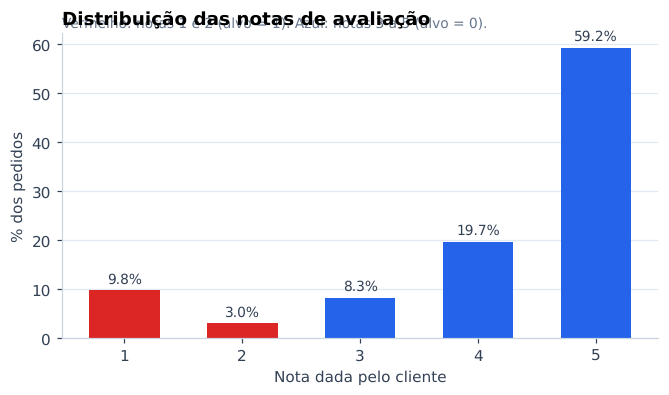

Avaliações negativas (nota 1 ou 2): 12.8% dos pedidos


In [7]:
taxa_base = base["negativa"].mean()
dist = base["review_score"].value_counts().sort_index()
perc = 100 * dist / dist.sum()

fig, ax = plt.subplots(figsize=(7, 3.6))
cores = [VERMELHO if nota <= 2 else AZUL for nota in dist.index]
barras = ax.bar(dist.index.astype(str), perc, color=cores, width=0.6)
ax.bar_label(barras, labels=[f"{p:.1f}%" for p in perc], padding=3, color="#334155", fontsize=9)
ax.set_title("Distribuição das notas de avaliação")
ax.set_xlabel("Nota dada pelo cliente")
ax.set_ylabel("% dos pedidos")
ax.grid(axis="x", visible=False)
ax.text(0.0, 1.02, "Vermelho: notas 1 e 2 (alvo = 1). Azul: notas 3 a 5 (alvo = 0).",
        transform=ax.transAxes, fontsize=9, color="#64748b")
salvar(fig, "01_distribuicao_notas.png")
plt.show()

print(f"Avaliações negativas (nota 1 ou 2): {100 * taxa_base:.1f}% dos pedidos")

**Leitura.** A maioria dos clientes está satisfeita: 59,2% deram nota 5 e 19,7% nota 4. As notas 1 e 2 somam **12,8%** (9,8% + 3,0%). Quem fica insatisfeito tende a ir direto para a nota mínima: a nota 1 é três vezes mais comum que a 2.

Isso define a avaliação do modelo: com classes desbalanceadas, **acurácia engana**. Um "modelo" que sempre responde "não vai ser negativa" acerta cerca de 87% e não ajuda em nada. Por isso, no notebook 02, olhamos recall, precisão, F1 e PR-AUC.

## 5. Nota vs. atraso na entrega

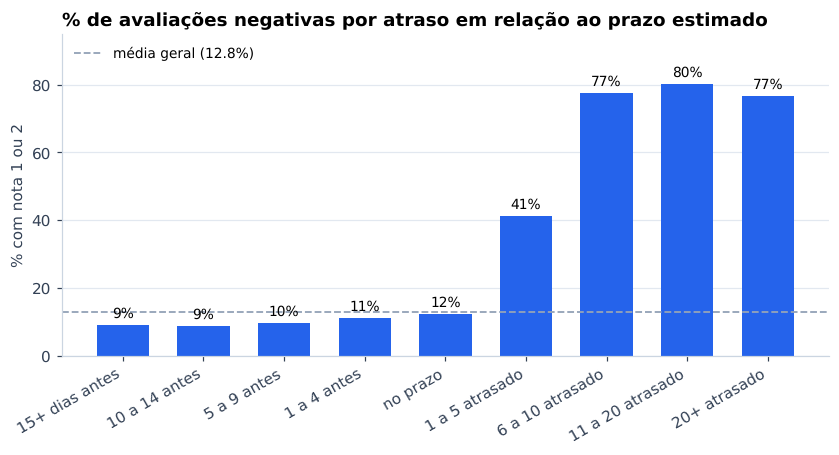

,pedidos,perc_negativa,perc_pedidos
faixa_atraso,,,
15+ dias antes,34771,9.0,36.3
10 a 14 antes,26752,8.7,27.9
5 a 9 antes,20032,9.6,20.9
1 a 4 antes,6608,11.2,6.9
no prazo,1280,12.4,1.3
1 a 5 atrasado,2722,41.1,2.8
6 a 10 atrasado,1634,77.5,1.7
11 a 20 atrasado,1261,80.3,1.3
20+ atrasado,763,76.5,0.8


In [8]:
faixas = [-np.inf, -15, -10, -5, -1, 0, 5, 10, 20, np.inf]
rotulos = ["15+ dias antes", "10 a 14 antes", "5 a 9 antes", "1 a 4 antes", "no prazo",
           "1 a 5 atrasado", "6 a 10 atrasado", "11 a 20 atrasado", "20+ atrasado"]
base["faixa_atraso"] = pd.cut(base["dias_atraso"], bins=faixas, labels=rotulos)
por_atraso = base.groupby("faixa_atraso", observed=True).agg(
    pedidos=("negativa", "size"), perc_negativa=("negativa", "mean"))
por_atraso["perc_negativa"] *= 100
por_atraso["perc_pedidos"] = 100 * por_atraso["pedidos"] / len(base)

fig, ax = plt.subplots(figsize=(9, 3.8))
barras = ax.bar(por_atraso.index.astype(str), por_atraso["perc_negativa"], color=AZUL, width=0.65)
ax.bar_label(barras, labels=[f"{p:.0f}%" for p in por_atraso["perc_negativa"]], padding=3, fontsize=9)
linha_taxa_base(ax, taxa_base)
ax.set_title("% de avaliações negativas por atraso em relação ao prazo estimado")
ax.set_ylabel("% com nota 1 ou 2")
ax.set_ylim(0, 95)
ax.tick_params(axis="x", rotation=30)
for lbl in ax.get_xticklabels():
    lbl.set_ha("right")
ax.grid(axis="x", visible=False)
salvar(fig, "02_negativa_por_atraso.png")
plt.show()
por_atraso.round(1)

**Leitura.** É o sinal mais forte do dataset. Pedidos entregues antes do prazo têm de 9% a 11% de notas negativas, e no prazo, 12%. Com 1 a 5 dias de atraso a taxa sobe para **41%**, e a partir de 6 dias passa de **75%**. Só 6,7% dos pedidos atrasam, mas eles concentram uma grande parte das notas negativas. A relação é um "degrau" no prazo e não uma reta, o que favorece modelos de árvore em relação à Regressão Logística.

## 6. Nota vs. frete

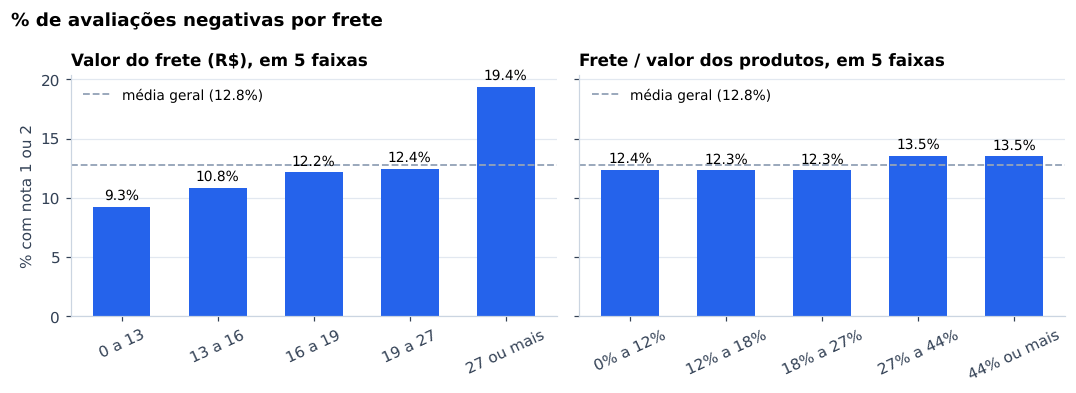

In [9]:
base["faixa_frete"] = pd.qcut(base["valor_frete"], q=5)
base["faixa_frete_rel"] = pd.qcut(base["frete_sobre_valor"], q=5)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, col, titulo, fmt in [
    (axes[0], "faixa_frete", "Valor do frete (R$), em 5 faixas", lambda i: f"{i.left:.0f} a {i.right:.0f}"),
    (axes[1], "faixa_frete_rel", "Frete / valor dos produtos, em 5 faixas", lambda i: f"{100*i.left:.0f}% a {100*i.right:.0f}%"),
]:
    g = 100 * base.groupby(col, observed=True)["negativa"].mean()
    rot = [fmt(i) for i in g.index]
    rot[0] = rot[0].replace("-", "")
    rot[-1] = rot[-1].split(" a ")[0] + " ou mais"
    barras = ax.bar(rot, g.values, color=AZUL, width=0.6)
    ax.bar_label(barras, labels=[f"{v:.1f}%" for v in g.values], padding=3, fontsize=9)
    linha_taxa_base(ax, taxa_base)
    ax.set_title(titulo, fontsize=11)
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% com nota 1 ou 2")
fig.suptitle("% de avaliações negativas por frete", x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
salvar(fig, "03_negativa_por_frete.png")
plt.show()

**Leitura.** Frete mais caro em reais acompanha mais notas negativas: 9,3% na faixa mais barata e 19,4% acima de R$ 27. Já a proporção frete/valor quase não muda a taxa (de 12,3% a 13,5%). A explicação provável é que frete alto indica produto grande ou pesado, ou cliente longe do vendedor, ou seja, entregas mais difíceis. Não parece ser o "preço" do frete em si que irrita o cliente.

## 7. Nota por categoria do produto

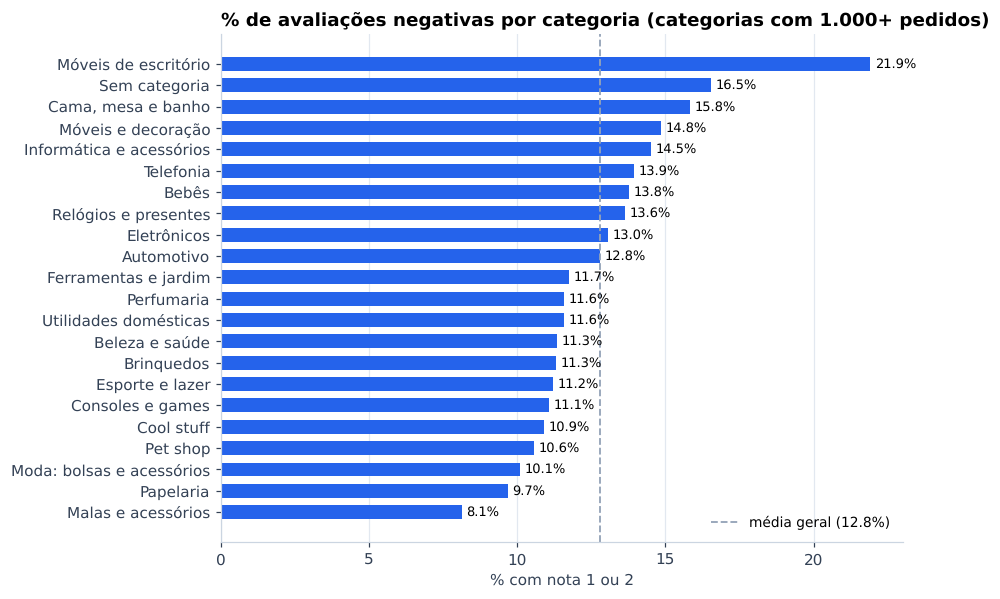

Categorias com 1.000+ pedidos: 22 de 74


In [10]:
por_cat = base.groupby("categoria").agg(pedidos=("negativa", "size"), perc=("negativa", "mean"))
top = por_cat[por_cat["pedidos"] >= 1000].sort_values("perc")
top["perc"] *= 100
top.index = [nome_categoria(c) for c in top.index]

fig, ax = plt.subplots(figsize=(8, 6))
barras = ax.barh(top.index, top["perc"], color=AZUL, height=0.65)
ax.bar_label(barras, labels=[f"{p:.1f}%" for p in top["perc"]], padding=3, fontsize=8.5)
linha_taxa_base(ax, taxa_base, horizontal=False)
ax.set_title("% de avaliações negativas por categoria (categorias com 1.000+ pedidos)")
ax.set_xlabel("% com nota 1 ou 2")
ax.grid(axis="y", visible=False)
salvar(fig, "04_negativa_por_categoria.png")
plt.show()
print(f"Categorias com 1.000+ pedidos: {len(top)} de {base['categoria'].nunique()}")

**Leitura.** A maioria das categorias fica perto da média. Acima dela: móveis de escritório (21,9%), pedidos sem categoria (16,5%) e cama, mesa e banho (15,8%). Abaixo: malas e acessórios (8,1%) e papelaria (9,7%). Móveis são produtos grandes, com entrega e montagem mais difíceis. O efeito da categoria existe, mas é bem menor que o do atraso.

## 8. Nota por UF do cliente

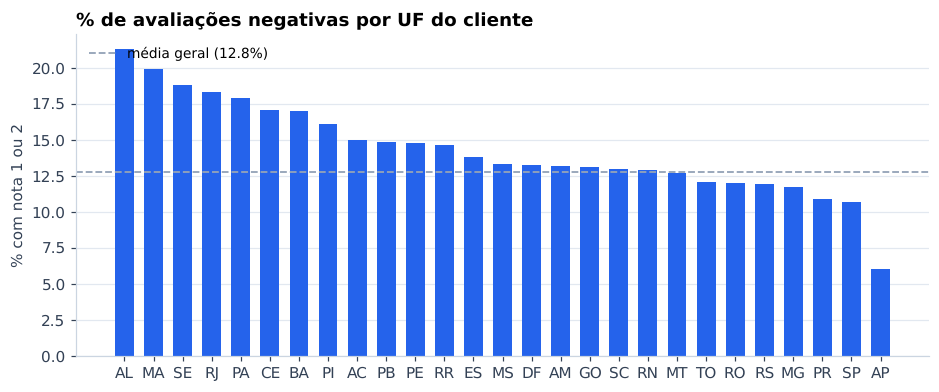

uf_cliente,AL,MA,SE,RJ,PA,CE,BA,PI,AC,PB,PE,RR,ES,MS,DF,AM,GO,SC,RN,MT,TO,RO,RS,MG,PR,SP,AP
pedidos,394.0,712.0,334.0,12211.0,933.0,1273.0,3229.0,471.0,80.0,512.0,1579.0,41.0,1969.0,699.0,2070.0,144.0,1946.0,3519.0,471.0,879.0,273.0,242.0,5326.0,11285.0,4900.0,40265.0,66.0
perc,21.3,19.9,18.9,18.3,17.9,17.1,17.0,16.1,15.0,14.8,14.8,14.6,13.8,13.3,13.2,13.2,13.2,13.0,13.0,12.7,12.1,12.0,11.9,11.8,10.9,10.7,6.1


In [11]:
por_uf = base.groupby("uf_cliente").agg(pedidos=("negativa", "size"), perc=("negativa", "mean"))
por_uf["perc"] *= 100
por_uf = por_uf.sort_values("perc", ascending=False)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(por_uf.index, por_uf["perc"], color=AZUL, width=0.65)
linha_taxa_base(ax, taxa_base)
ax.set_title("% de avaliações negativas por UF do cliente")
ax.set_ylabel("% com nota 1 ou 2")
ax.grid(axis="x", visible=False)
salvar(fig, "05_negativa_por_uf.png")
plt.show()
por_uf.T.round(1)

**Leitura.** Clientes de AL (21,3%), MA (19,9%), SE (18,9%) e RJ (18,3%) dão mais notas negativas. SP (10,7%) e PR (10,9%) ficam abaixo da média. Como a maioria dos vendedores está em SP, quem mora longe recebe com prazos maiores e mais atrasos. Atenção: AP (66 pedidos), RR (41) e AC (80) têm poucos pedidos, então a taxa deles é instável.

## 9. Outras relações: quantidade de itens e vendedor em outro estado

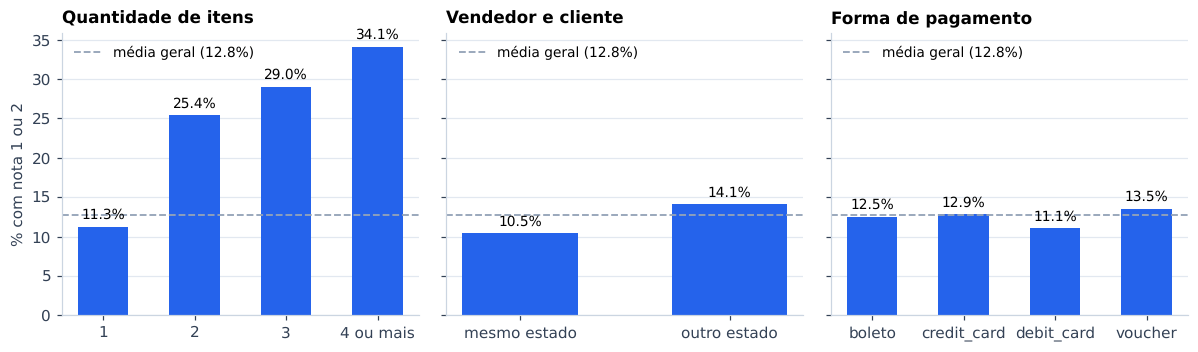

itens_faixa
1            90.1
2             7.6
3             1.3
4 ou mais     1.0
Name: proportion, dtype: float64


In [12]:
base["itens_faixa"] = base["qtd_itens"].clip(upper=4).map({1: "1", 2: "2", 3: "3", 4: "4 ou mais"})
itens = 100 * base.groupby("itens_faixa")["negativa"].mean()
estados = 100 * base.groupby("estados_diferentes")["negativa"].mean().rename({0: "mesmo estado", 1: "outro estado"})
pag = 100 * base.groupby("pagamento")["negativa"].mean()

fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), sharey=True)
for ax, serie, titulo in [(axes[0], itens, "Quantidade de itens"),
                          (axes[1], estados, "Vendedor e cliente"),
                          (axes[2], pag, "Forma de pagamento")]:
    barras = ax.bar(serie.index.astype(str), serie.values, color=AZUL, width=0.55)
    ax.bar_label(barras, labels=[f"{v:.1f}%" for v in serie.values], padding=3, fontsize=9)
    linha_taxa_base(ax, taxa_base)
    ax.set_title(titulo, fontsize=11)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% com nota 1 ou 2")
fig.tight_layout()
salvar(fig, "06_negativa_itens_estado_pagamento.png")
plt.show()
print(base["itens_faixa"].value_counts(normalize=True).sort_index().mul(100).round(1))

**Leitura.** A quantidade de itens tem efeito claro: 11,3% de negativas com 1 item, 25,4% com 2 e 34,1% com 4 ou mais (mais chance de faltar um item ou de chegar em entregas separadas). Vendedor em outro estado: 14,1% contra 10,5% no mesmo estado. A forma de pagamento quase não muda a taxa (de 11,1% a 13,5%).

## 10. Um cuidado: avaliações feitas antes da entrega

O Olist envia a pesquisa perto da data estimada. Alguns clientes avaliaram **antes** de o pedido chegar (normalmente reclamando do atraso). Nesses casos, o atraso real só foi conhecido depois da nota. Medimos quantos são:

In [13]:
antes = base.groupby("avaliou_antes_entrega")["negativa"].agg(["size", "mean"])
antes.index = ["avaliou depois da entrega", "avaliou antes da entrega"]
antes.columns = ["pedidos", "% negativa"]
antes["% negativa"] *= 100
antes["% dos pedidos"] = 100 * antes["pedidos"] / len(base)
antes.round(1)

,pedidos,% negativa,% dos pedidos
avaliou depois da entrega,90848,9.5,94.8
avaliou antes da entrega,4975,72.6,5.2


**Decisão.** 5,2% dos clientes avaliaram antes de receber, e 72,6% deles deram nota 1 ou 2. Quase todos (95%) eram pedidos atrasados: o cliente reclamou enquanto esperava. Esse grupo responde por **29% de todas as notas negativas**.

**Mantivemos esses pedidos** porque eles representam um caso real e importante para o atendimento: o pedido passou do prazo e o cliente está esperando. Na prática, isso significa que o alerta de um pedido atrasado deve ser disparado **assim que o prazo estimado vence**, sem esperar a entrega. No notebook 02 medimos o desempenho com e sem esse grupo, para não superestimar o modelo.

## 11. Resumo da EDA

- Base final: **95.823 pedidos** entregues e avaliados, de 10/2016 a 08/2018.
- **12,8%** têm nota 1 ou 2: classes desbalanceadas, então a acurácia não serve como métrica.
- **Atraso** é de longe o fator mais forte (de cerca de 10% para mais de 75% de negativas).
- Quantidade de itens, frete em reais, vendedor em outro estado, UF do cliente e categoria têm efeitos menores, mas consistentes.
- Forma de pagamento e frete/valor quase não mudam a taxa.
- Valores extremos foram mantidos, e texto e datas da avaliação ficaram fora (vazamento de alvo).

Próximo passo: `02_modelagem_avaliacao.ipynb`.